# 模块7：卖家获取漏斗（精简版）

**业务问题：** 新卖家从线索到稳定经营，哪一步流失最多？哪个获客渠道带来的卖家质量最好？

**数据：** `dws_seller_funnel`（8,000 条营销线索，一行一条；842 个签约卖家通过 `seller_id` 关联订单数据）

**口径（D-031）：** 激活 = 签约后 90 天内 ≥ 1 笔有效订单；健康 = ≥ 3 笔；只有签约满 90 天观察期的 667 个签约计算激活与健康

**结论：** 详见 `docs/stage_summaries/stage_2.md` 模块7。

In [8]:
from olist_utils import run_query, set_style, COLORS
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
set_style()

## 7.1 整体漏斗

查看整体漏斗: 每一步漏多少

In [9]:
#漏斗数据
sql_funnel = """
SELECT COUNT(*)              AS n_mql,
       SUM(is_won)           AS n_won,
       SUM(is_observable)    AS n_observable,
       SUM(is_activated_90d) AS n_activated,
       SUM(is_healthy_90d)   AS n_healthy
FROM dws_seller_funnel
"""
f = run_query(sql_funnel).astype(float).iloc[0]

# 每一步的转化率，各自使用正确的基数
rate_won       = f["n_won"]       / f["n_mql"]          # 线索 → 签约（全部线索）
rate_activated = f["n_activated"] / f["n_observable"]   # 签约 → 激活（只用观察期完整的签约，D-031）
rate_healthy   = f["n_healthy"]   / f["n_activated"]    # 激活 → 健康

# 连乘折算成"每 1,000 条线索"
stages   = ["线索 MQL", "签约", "激活\n(90天内≥1单)", "健康\n(90天内≥3单)"]
per_1000 = [1000,
            1000 * rate_won,
            1000 * rate_won * rate_activated,
            1000 * rate_won * rate_activated * rate_healthy]
step_rate = [None, rate_won, rate_activated, rate_healthy]
df_funnel = pd.DataFrame({"stage": stages, "per_1000": per_1000, "step_rate": step_rate})
print(df_funnel)

# 各阶段耗时
sql_days = """
SELECT days_to_won, days_to_first_order
FROM dws_seller_funnel
WHERE is_won = 1
"""
days = run_query(sql_days)
print("线索→签约 中位天数：", days["days_to_won"].median())
print("签约→首单 中位天数：", days["days_to_first_order"].median())

           stage     per_1000  step_rate
0         线索 MQL  1000.000000        NaN
1             签约   105.250000   0.105250
2  激活\n(90天内≥1单)    45.445277   0.431784
3  健康\n(90天内≥3单)    23.511619   0.517361
线索→签约 中位天数： 14.0
签约→首单 中位天数： 39.0


In [10]:
# 累计激活曲线：签约后第 N 天，累计有多少比例的卖家已卖出第一单
# 分母是全部观察期完整的签约（667 个），没激活的卖家 days_to_first_order 为 NULL，记为"未激活"
sql_curve = """
SELECT t.d                                                     AS days_after_won,
       ROUND(AVG(COALESCE(f.days_to_first_order <= t.d, 0)), 3) AS cum_activated
FROM dws_seller_funnel f
CROSS JOIN (SELECT 7 AS d UNION ALL SELECT 15 UNION ALL SELECT 30 UNION ALL SELECT 45
            UNION ALL SELECT 60 UNION ALL SELECT 75 UNION ALL SELECT 90) t
WHERE f.is_observable = 1
GROUP BY t.d
ORDER BY t.d
"""
run_query(sql_curve)

,days_after_won,cum_activated
0,7,0.028
1,15,0.072
2,30,0.165
3,45,0.250
4,60,0.322
5,75,0.384
6,90,0.432


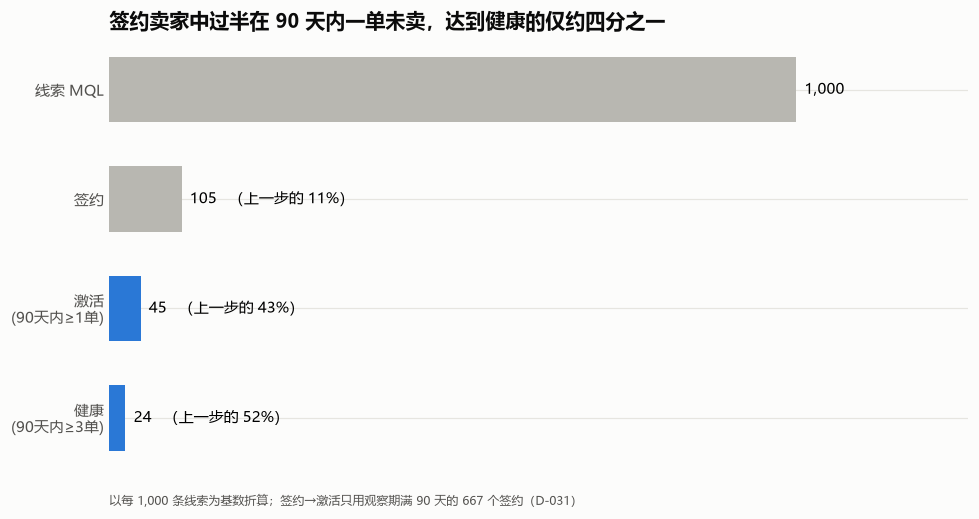

In [11]:
#漏斗图
fig, ax = plt.subplots(figsize=(9, 4.8))
y = np.arange(len(df_funnel))[::-1]                     # 第一级画在最上面
colors = [COLORS["gray"], COLORS["gray"],               # 签约前：营销与销售
          COLORS["blue"], COLORS["blue"]]               # 签约后：入驻运营
ax.barh(y, df_funnel["per_1000"], color=colors, height=0.6)

for yi, v, r in zip(y, df_funnel["per_1000"], df_funnel["step_rate"]):
    label = f"{v:,.0f}" if pd.isna(r) else f"{v:,.0f}   （上一步的 {r:.0%}）"
    ax.text(v + 12, yi, label, va="center", fontsize=10)

ax.set_yticks(y)
ax.set_yticklabels(df_funnel["stage"])
ax.set_xlim(0, 1250)
ax.set_xticks([])                                       # 数字已直接标在柱子旁，不需要横轴刻度
for s in ["left", "bottom", "top", "right"]:
    ax.spines[s].set_visible(False)
ax.set_title("签约卖家中过半在 90 天内一单未卖，达到健康的仅约四分之一", loc="left")
ax.text(0.0, -0.08,
        "以每 1,000 条线索为基数折算；签约→激活只用观察期满 90 天的 667 个签约（D-031）",
        transform=ax.transAxes, fontsize=8, color=COLORS["text_secondary"])

fig.tight_layout()
fig.savefig("../docs/figures/m7_funnel.png", dpi=150, bbox_inches="tight")
plt.show()



## 7.2 渠道质量

分析渠道质量

两个指标: 1. 数量指标 线索->签约的转化率; 2. 质量指标 签约->90天内激活比例

两者合成一个综合指标: 每 1,000 条线索最终能带来几个健康卖家（= 签约率 × 健康率 × 1,000）

处理细节: 将小渠道合并成“其他渠道”, 避免误差太大

In [12]:
# 按渠道汇总
sql_channel = """
WITH ch AS (
    -- 观察期完整的签约 < 30 个的渠道，合并为"其他渠道"
    SELECT f.*,
           CASE WHEN o.n_obs >= 30 THEN f.origin ELSE '其他渠道（合并）' END AS channel
    FROM dws_seller_funnel f
    JOIN (SELECT origin, SUM(is_observable) AS n_obs
          FROM dws_seller_funnel
          GROUP BY origin) o
      ON f.origin = o.origin
)
SELECT channel,
       COUNT(*)              AS n_mql,
       SUM(is_won)           AS n_won,
       SUM(is_observable)    AS n_obs,
       SUM(is_activated_90d) AS n_activated,
       SUM(is_healthy_90d)   AS n_healthy
FROM ch
GROUP BY channel
"""
df_ch = run_query(sql_channel)
num = ["n_mql", "n_won", "n_obs", "n_activated", "n_healthy"]
df_ch[num] = df_ch[num].astype(int)

df_ch["win_rate"]     = df_ch["n_won"]       / df_ch["n_mql"]   # 数量：线索 → 签约
df_ch["act_rate"]     = df_ch["n_activated"] / df_ch["n_obs"]   # 质量：签约 → 激活（观察期完整的签约）
df_ch["healthy_rate"] = df_ch["n_healthy"]   / df_ch["n_obs"]
df_ch["healthy_per_1000_mql"] = 1000 * df_ch["win_rate"] * df_ch["healthy_rate"]   # 综合指标

def ci_half(p, n, z=1.96):
    """95% 置信区间的半宽：p ± ci_half"""
    return z * np.sqrt(p * (1 - p) / n)

df_ch["win_ci"] = ci_half(df_ch["win_rate"], df_ch["n_mql"])
df_ch["act_ci"] = ci_half(df_ch["act_rate"], df_ch["n_obs"])

df_ch = df_ch.sort_values("n_mql", ascending=False).reset_index(drop=True)
df_ch[["channel", "n_mql", "n_won", "n_obs", "win_rate", "act_rate",
       "healthy_rate", "healthy_per_1000_mql"]].round(3)

,channel,n_mql,n_won,n_obs,win_rate,act_rate,healthy_rate,healthy_per_1000_mql
0,organic_search,2296,271,208,0.118,0.389,0.207,24.401
1,paid_search,1586,195,146,0.123,0.548,0.260,32.001
2,social,1350,75,55,0.056,0.436,0.200,11.111
3,unknown,1159,193,165,0.167,0.400,0.224,37.341
4,其他渠道（合并）,1110,52,44,0.047,0.341,0.205,9.582
5,direct_traffic,499,56,49,0.112,0.449,0.224,25.193


In [13]:
#显著性检验
import math
from scipy.stats import norm

def two_prop_ztest(k1, n1, k2, n2):
    """两比例 z 检验（与 3.5 相同）：返回 差值、z、p"""
    p1, p2 = k1 / n1, k2 / n2
    p_pool = (k1 + k2) / (n1 + n2)
    se = math.sqrt(p_pool * (1 - p_pool) * (1 / n1 + 1 / n2))
    z = (p2 - p1) / se
    return round(p2 - p1, 4), round(z, 2), round(2 * (1 - norm.cdf(abs(z))), 4)

g = df_ch.set_index("channel")      # 按渠道名取数，不依赖行的顺序（3.5 的教训）
tests = [   # (名称, 分子列, 分母列, 渠道A, 渠道B)
    ("签约率：自然搜索 vs 付费搜索", "n_won",       "n_mql", "organic_search", "paid_search"),
    ("签约率：自然搜索 vs 社交媒体", "n_won",       "n_mql", "organic_search", "social"),
    ("激活率：自然搜索 vs 付费搜索", "n_activated", "n_obs", "organic_search", "paid_search"),
    ("健康率：自然搜索 vs 付费搜索", "n_healthy",   "n_obs", "organic_search", "paid_search"),
]
rows = []
for name, k, n, a, b in tests:
    diff, z, p = two_prop_ztest(g.loc[a, k], g.loc[a, n], g.loc[b, k], g.loc[b, n])
    rows.append({"比较": name, "差值": diff, "z": z, "p": p})
pd.DataFrame(rows)

,比较,差值,z,p
0,签约率：自然搜索 vs 付费搜索,0.0049,0.46,0.6429
1,签约率：自然搜索 vs 社交媒体,-0.0625,-6.22,0.0000
2,激活率：自然搜索 vs 付费搜索,0.1585,2.95,0.0032
3,健康率：自然搜索 vs 付费搜索,0.0535,1.18,0.2378


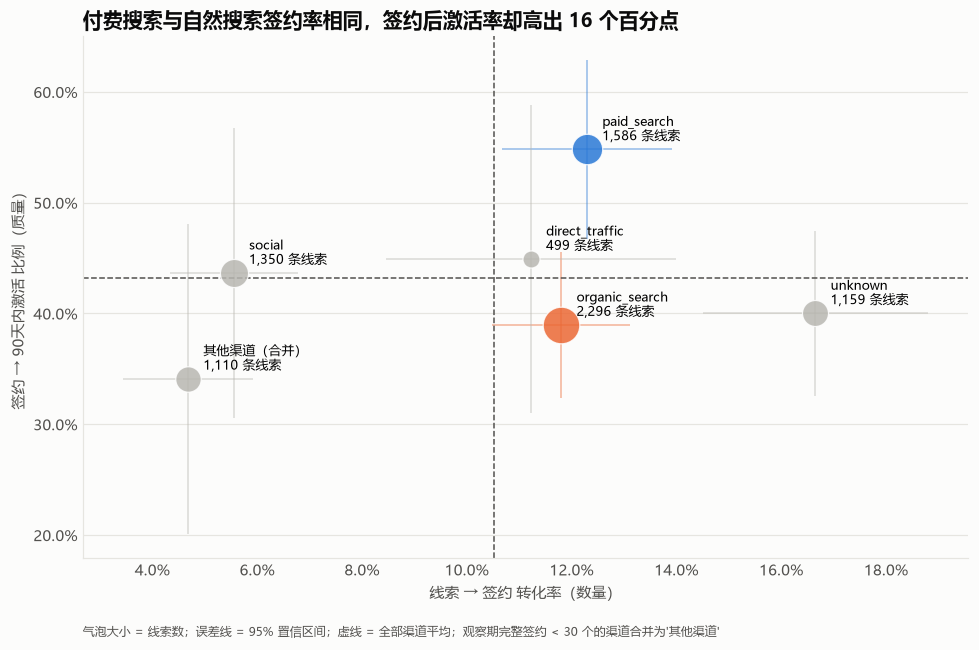

In [14]:
#数量 × 质量 散点图
fig, ax = plt.subplots(figsize=(9, 6))
highlight = {"paid_search": COLORS["blue"], "organic_search": COLORS["orange"]}   # 重点对比的两个渠道

for _, r in df_ch.iterrows():
    color = highlight.get(r["channel"], COLORS["gray"])
    # 误差线：95% 置信区间，越长越不可靠
    ax.errorbar(r["win_rate"], r["act_rate"], xerr=r["win_ci"], yerr=r["act_ci"],
                fmt="none", ecolor=color, alpha=0.5, linewidth=1, capsize=0)
    ax.scatter(r["win_rate"], r["act_rate"], s=r["n_mql"] / 4, color=color, alpha=0.85,
               edgecolors="white", linewidths=0.8, zorder=3)
    ax.annotate(f"{r['channel']}\n{r['n_mql']:,} 条线索", (r["win_rate"], r["act_rate"]),
                xytext=(10, 6), textcoords="offset points", fontsize=8.5)

# 全部渠道的平均水平（先合并个数再相除）
overall_win = df_ch["n_won"].sum()       / df_ch["n_mql"].sum()
overall_act = df_ch["n_activated"].sum() / df_ch["n_obs"].sum()
ax.axvline(overall_win, color=COLORS["text_secondary"], linestyle="--", linewidth=1)
ax.axhline(overall_act, color=COLORS["text_secondary"], linestyle="--", linewidth=1)

ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.set_xlabel("线索 → 签约 转化率（数量）")
ax.set_ylabel("签约 → 90天内激活 比例（质量）")
ax.set_title("付费搜索与自然搜索签约率相同，签约后激活率却高出 16 个百分点", loc="left")
ax.text(0.0, -0.15,
        "气泡大小 = 线索数；误差线 = 95% 置信区间；虚线 = 全部渠道平均；"
        "观察期完整签约 < 30 个的渠道合并为'其他渠道'",
        transform=ax.transAxes, fontsize=8, color=COLORS["text_secondary"])

fig.tight_layout()
fig.savefig("../docs/figures/m7_channel_quality.png", dpi=150, bbox_inches="tight")
plt.show()